# P2c — Mini-artigo · Tema T2: Condição de corrida com e sem mutex

**Alternativas comparadas:** Contador compartilhado sem e com mutex.  
**Parâmetro variado:** Número de threads.  
**Métricas:** Incrementos perdidos e passos executados.

## 1. Pergunta
**Pergunta:** Qual a quantidade de incrementos que se perde, em média, quando existe a disputa de 2, 4 e 8 threads por um mesmo contador sem sincronização, e quanto dessa perda é eliminada pelo mutex?

## 2. Método

O experimento usou uma simulação lógica em Python de um contador compartilhado por 2, 4 e 8 threads, com 100 incrementos por thread. Cada incremento foi dividido em três etapas: leitura do contador (LOAD), adição de uma unidade (ADD) e escrita do resultado (STORE). Avaliamos dois cenários: um sem sincronização e outro usando mutex para proteger a seção crítica. A cada passo, o simulador escolhia uma thread ativa de forma pseudoaleatória. No cenário com mutex, tentar iniciar um incremento com a trava ocupada consumia um passo sem avançar a execução. Testamos 20 sementes pseudoaleatórias fixadas de 0 a 19 para cada quantidade de threads e cada cenário, totalizando 120 simulações. Analisamos duas métricas: a média de incrementos perdidos, a diferença entre os incrementos esperados e o valor final do contador, e a média de passos lógicos registrados pelo simulador. Compilamos os dados em tabela e dois gráficos.

In [8]:
import random, math
import matplotlib.pyplot as plt

K = 100                  # incrementos que CADA thread deve concluir
THREADS = (2, 4, 8)      # parâmetro variado (número de threads)
SEMENTES = range(20)     # repetições: a média é feita sobre as sementes


In [9]:
def cria_threads(n_threads):
    return [
        {"instrucao": 0, "registrador": 0, "concluido": 0}
        for _ in range(n_threads)
    ]

In [10]:
def roda(n_threads, k, com_mutex, semente):

    random_case = random.Random(semente)
    contador = 0

    thread = cria_threads(n_threads)

    mutexOcupado = False
    passos = 0

    while any(t["concluido"] < k for t in thread):
        disponiveis = [
            i for i, t in enumerate(thread)
            if t["concluido"] < k
        ]

        i = random_case.choice(disponiveis)
        t = thread[i]

        passos += 1

        if com_mutex and t["instrucao"] == 0:
            if mutexOcupado:
                continue
            mutexOcupado = True

        if t["instrucao"] == 0:
            t["registrador"] = contador
            t["instrucao"] = 1

        elif t["instrucao"] == 1:
            t["registrador"] += 1
            t["instrucao"] = 2

        elif t["instrucao"] == 2:
            contador = t["registrador"]
            t["concluido"] += 1
            t["instrucao"] = 0

            if com_mutex:
                mutexOcupado = False

    incrementos_perdidos = n_threads * k - contador

    return incrementos_perdidos, passos

In [11]:
assert roda(1, 10, False, 0)[0] == 0
assert roda(4, 50, True, 0)[0] == 0
for s in range(50):
    for n in (1, 2, 3, 4, 8):
        assert roda(n, 30, True, s)[0] == 0       # propriedade: com mutex nunca perde
assert any(roda(4, 50, False, s)[0] > 0 for s in range(20))   # propriedade: sem mutex, ha perda em alguma semente


## 3. Resultados

In [12]:
tabela = []
for n in THREADS:
    esperado = n * K
    for com_mutex in (False, True):
        r = [roda(n, K, com_mutex, s) for s in SEMENTES]
        perdidos = sum(x[0] for x in r) / len(r)
        passos = sum(x[1] for x in r) / len(r)
        dp_perdidos = math.sqrt(sum((x[0] - perdidos) ** 2 for x in r) / (len(r) - 1))
        dp_passos = math.sqrt(sum((x[1] - passos) ** 2 for x in r) / (len(r) - 1))
        perda_pct = 100 * perdidos / esperado

        if not com_mutex:
            passos_sem = passos
            delta_p = "-"
        else:
            delta_p = f"{100 * (passos - passos_sem) / passos_sem:.2f}%"


        tabela.append((n, com_mutex, perdidos, passos))
        print(
            f"threads={n} mutex={com_mutex} esperado={esperado}: "
            f"perdidos={perdidos:.2f}±{dp_perdidos:.2f} ({perda_pct:.2f}%) | "
            f"passos={passos:.2f}±{dp_passos:.2f} | delta_P={delta_p}"
        )


threads=2 mutex=False esperado=200: perdidos=85.55±3.72 (42.77%) | passos=600.00±0.00 | delta_P=-
threads=2 mutex=True esperado=200: perdidos=0.00±0.00 (0.00%) | passos=973.40±23.54 | delta_P=62.23%
threads=4 mutex=False esperado=400: perdidos=272.45±7.85 (68.11%) | passos=1200.00±0.00 | delta_P=-
threads=4 mutex=True esperado=400: perdidos=0.00±0.00 (0.00%) | passos=3466.35±104.61 | delta_P=188.86%
threads=8 mutex=False esperado=800: perdidos=660.00±7.20 (82.50%) | passos=2400.00±0.00 | delta_P=-
threads=8 mutex=True esperado=800: perdidos=0.00±0.00 (0.00%) | passos=12981.95±178.62 | delta_P=440.91%


**Tabela 1:** Resultados das 20 execuções por configuração (sementes 0 a 19), com $K = 100$ incrementos por thread. DP: desvio-padrão amostral.

| $N$ | Mutex | Esperado | Perdas (média ± DP) | Perda (%) | Passos (média ± DP) | $\Delta P$ (%) |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 2 | Não | 200 | 85,55 ± 3,72 | 42,78 | 600,00 ± 0 | — |
| 2 | Sim | 200 | 0 ± 0 | 0 | 973,40 ± 23,54 | 62,23 |
| 4 | Não | 400 | 272,45 ± 7,85 | 68,11 | 1.200,00 ± 0 | — |
| 4 | Sim | 400 | 0 ± 0 | 0 | 3.466,35 ± 104,61 | 188,86 |
| 8 | Não | 800 | 660,00 ± 7,20 | 82,50 | 2.400,00 ± 0 | — |
| 8 | Sim | 800 | 0 ± 0 | 0 | 12.981,95 ± 178,62 | 440,91 |

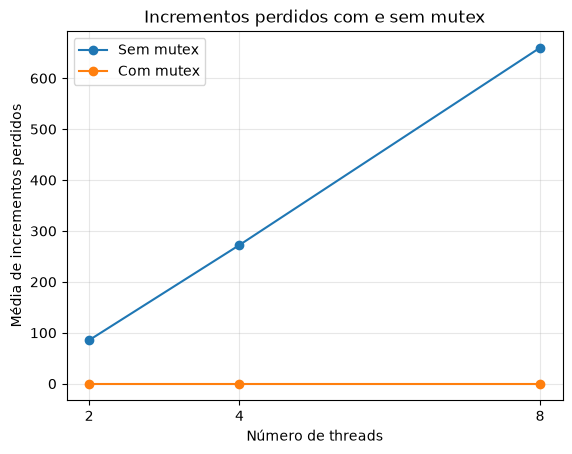

In [13]:
for m in (False, True):
    plt.plot([t[0] for t in tabela if t[1] == m], [t[2] for t in tabela if t[1] == m], marker="o", label="Com mutex" if m else "Sem mutex")
plt.xlabel("Número de threads")
plt.ylabel("Média de incrementos perdidos")
plt.xticks(THREADS)
plt.title("Incrementos perdidos com e sem mutex")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Figura 1:** Média de incrementos perdidos em função do número de threads (2, 4 e 8), comparando os cenários sem e com mutex. Cada ponto corresponde à média de 20 simulações, com 100 incrementos por thread. O eixo horizontal representa a quantidade de threads; o eixo vertical, a média de incrementos perdidos.

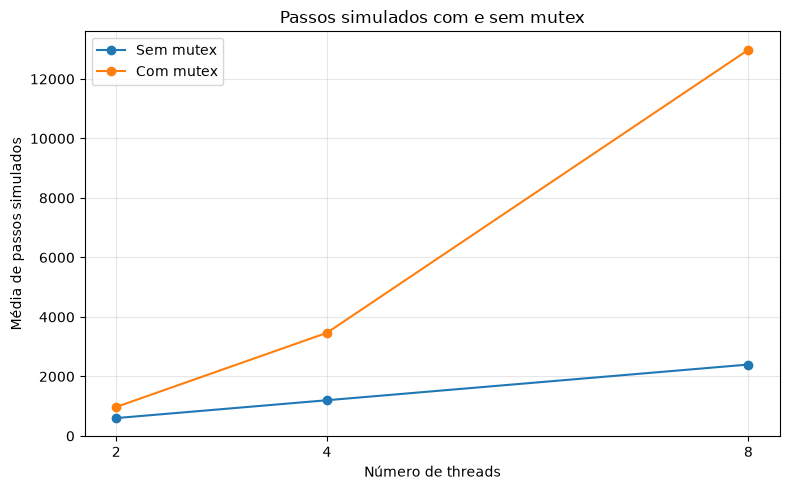

In [14]:
plt.figure(figsize=(8, 5))
for m in (False, True):
    plt.plot(
        [t[0] for t in tabela if t[1] == m],
        [t[3] for t in tabela if t[1] == m],
        marker="o",
        label="Com mutex" if m else "Sem mutex"
    )
plt.xlabel("Número de threads")
plt.ylabel("Média de passos simulados")
plt.title("Passos simulados com e sem mutex")
plt.xticks(THREADS)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Figura 2:** Média de passos lógicos contabilizados pelo simulador em função do número de threads (2, 4 e 8), comparando os cenários com e sem mutex. Cada ponto representa a média de 20 simulações, com 100 incrementos por thread.

## 4. Discussão

Os resultados demonstram que a perda média de incrementos aumenta conforme cresce o número de threads no cenário sem sincronização. Com 2 threads, a perda média foi de 85,55 incrementos (42,78% do total esperado). Com 4 threads, esse valor subiu para 272,45 (68,11%). Com 8 threads, atingiu 660 incrementos, representando 82,5% do total. O uso de mutex, em contrapartida, eliminou totalmente as perdas.

Esse padrão decorre de condições de corrida. Como a operação de incremento exige três etapas distintas (LOAD, ADD e STORE), threads concorrentes podem ler o mesmo valor em memória antes da conclusão da escrita anterior. Consequentemente, a instrução STORE de uma thread sobrescreve o resultado da outra, descartando incrementos.

O mutex impõe exclusão mútua na seção crítica, impedindo o entrelaçamento dessas instruções. Embora garanta a consistência do contador, o mecanismo eleva o volume de passos simulados devido às tentativas sem avanço quando o mutex está ocupado. Com 8 threads, a média alcançou cerca de 12.982 passos com mutex, em comparação a 2.400 no cenário sem proteção.

Um aumento no número de threads além de 8 elevaria a contenção pela memória e pelo mutex. A validação quantitativa dessa tendência requer novas simulações.

## 5. Limitações e conclusão

**Limitações:** Este experimento é uma simulação lógica em Python. Ele não reproduz o escalonamento, a execução paralela de threads ou o comportamento de memória de um sistema operacional real. A exclusão mútua é representada de forma simplificada, e os passos lógicos computados não equivalem diretamente a tempo de execução ou custo de processamento. Os resultados se limitam às configurações de 2, 4 e 8 threads e às 20 sementes analisadas por cenário.

**Conclusão:** Nas configurações testadas, a falta de sincronização causou perdas médias crescentes de incrementos conforme o número de threads aumentou, enquanto o mutex eliminou todas as perdas observadas. Embora a proteção tenha elevado a quantidade média de passos lógicos, ela garantiu a consistência do contador no modelo avaliado.

## Declaração de uso de IA

A equipe utilizou o **Gemini** (Google) como ferramenta de apoio para conferir a consistência dos resultados numéricos da Tabela 1 com as saídas geradas pelo código Python, validar as fórmulas matemáticas aplicadas no estudo e revisar a clareza textual das seções de Discussão e Conclusão. Todos os cálculos e resultados foram conferidos manualmente por meio da reexecução completa do notebook e da verificação das asserções (`assert`) do simulador.